In [3]:
import json
import os

import gizmo_analysis as gizmo
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy.stats import gaussian_kde
from sklearn.svm import SVC

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [4]:
sim_dir = "/Users/z5114326/Documents/simulations/"
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]

snap = 600

public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == snap]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])
pub_tims = np.array(pub_data["time_Gyr"])

all_data_fil = sim_dir + "/" + "m12i" + "/" + "m12i" + "_res7100/" + "snapshot_times.txt"
all_data = pd.read_table(all_data_fil, comment="#", header=None, sep=r"\s+")
all_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
all_times = np.array(all_data["time_Gyr"])
all_snaps = np.array(all_data["index"])

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

In [5]:
step = 2

rbins = np.arange(0, 100 + step, step)
rcens = rbins[:-1] + step / 2
vols = (4 / 3) * np.pi * rbins**3
dvol = np.diff(vols)

res_dict = {sim: {"mass": [], "dens": []} for sim in sim_lst}

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]
        r3d = np.linalg.norm(src_dat["pxyz_snap600"], axis=1)

        mfor = 10 ** src_dat["logm_tfor"][()]
        mfor_evs = 0.55 * mfor
        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
        mdifs = mfor_evs - mz0

        mbinned = np.zeros(len(rbins) - 1)
        for i in range(1, len(rbins)):
            rmin = rbins[i - 1]
            rmax = rbins[i]

            rmsk = (rmin < r3d) & (r3d <= rmax)
            mbinned[i - 1] = np.sum(mdifs[rmsk])

        res_dict[sim]["mass"].append(mbinned)
        res_dict[sim]["dens"].append(mbinned / dvol)

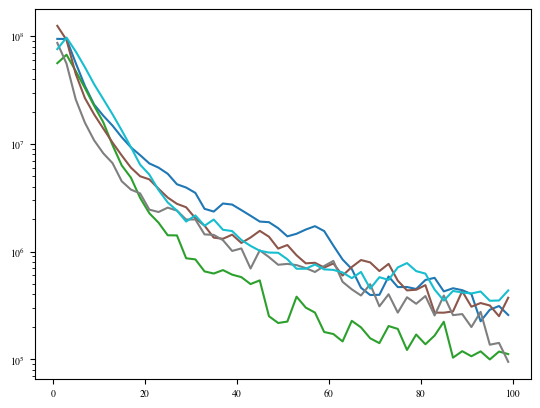

In [6]:
for sim in sim_lst:
    y = np.mean(res_dict[sim]["mass"], axis=0)

    plt.plot(rcens, y, c=sim_colors[sim])

plt.yscale("log")

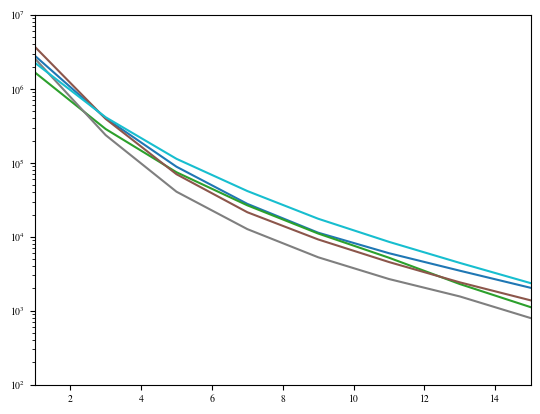

In [7]:
plt.xlim(1, 15)
plt.ylim(10**2, 10**7)

for sim in sim_lst:
    y = np.mean(res_dict[sim]["dens"], axis=0)

    plt.plot(rcens, y, c=sim_colors[sim])

plt.yscale("log")

# Orbital times

(array([8.579e+03, 2.737e+03, 1.289e+03, 6.710e+02, 3.720e+02, 3.430e+02,
        2.940e+02, 3.250e+02, 2.150e+02, 1.270e+02, 8.600e+01, 7.700e+01,
        5.500e+01, 6.100e+01, 6.500e+01, 5.000e+01, 6.700e+01, 3.900e+01,
        3.900e+01, 3.800e+01, 4.400e+01, 6.300e+01, 3.800e+01, 4.600e+01,
        2.700e+01, 2.900e+01, 2.600e+01, 2.500e+01, 2.000e+01, 2.400e+01,
        2.300e+01, 1.700e+01, 6.000e+00, 1.400e+01, 1.700e+01, 7.000e+00,
        9.000e+00, 1.700e+01, 6.000e+00, 3.000e+00]),
 array([   0.,  100.,  200.,  300.,  400.,  500.,  600.,  700.,  800.,
         900., 1000., 1100., 1200., 1300., 1400., 1500., 1600., 1700.,
        1800., 1900., 2000., 2100., 2200., 2300., 2400., 2500., 2600.,
        2700., 2800., 2900., 3000., 3100., 3200., 3300., 3400., 3500.,
        3600., 3700., 3800., 3900., 4000.]),
 <BarContainer object of 40 artists>)

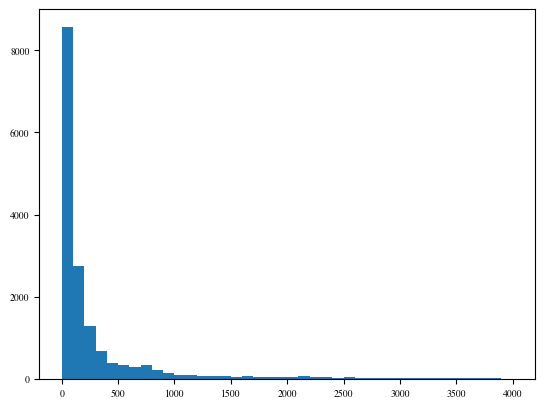

In [15]:
ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
ghost_data = h5py.File(ghost_file, "r")

src_dat = ghost_data[it_id]["source"]

bins = np.arange(0, 4100, 100)

plt.hist(src_dat["torb_600"][()], bins=bins)

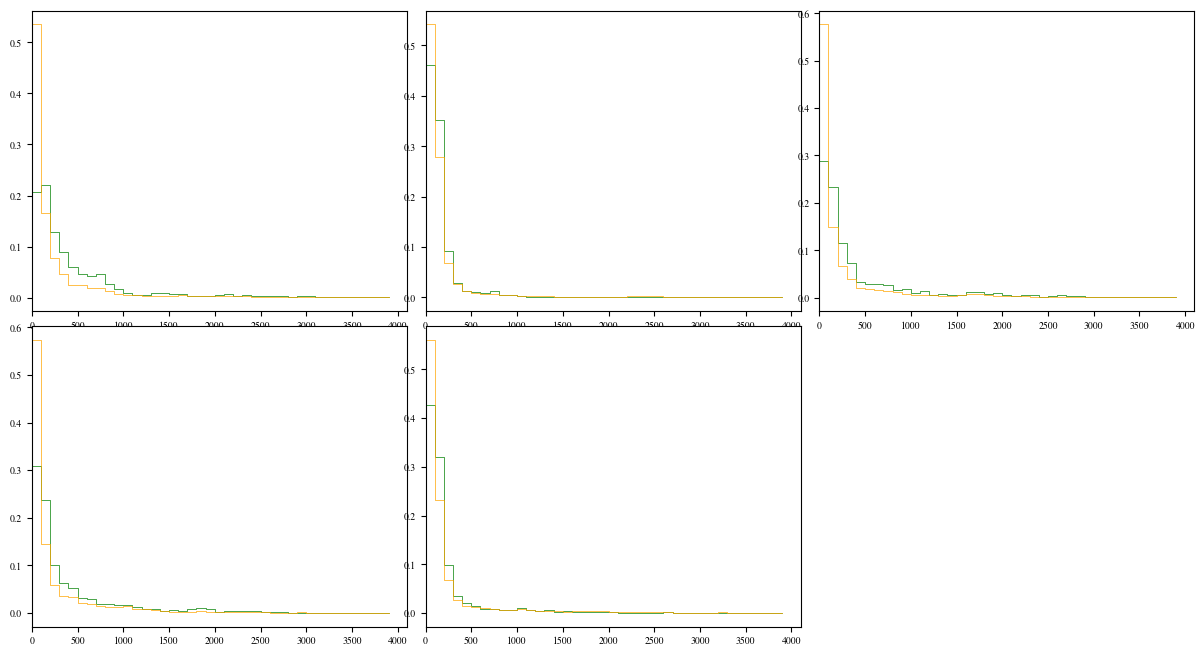

In [27]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

bins = np.arange(0, 4100, 100)

for i, ax in enumerate(axs.flatten()):
    if i == 5:
        ax.axis("off")
        continue

    sim = sim_lst[i]

    # for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    hist_dict = {"sum_sur": None, "sum_dis": None, "n": 0}

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        smsk = src_dat["tdis"][()] != -1

        tsurv = src_dat["torb_600"][~smsk]
        tdiss = src_dat["torb_600"][smsk]

        hssp_for, _ = np.histogram(tsurv, bins=bins)
        hssp_dis, _ = np.histogram(tdiss, bins=bins)

        if hist_dict["sum_sur"] is None:
            hist_dict["sum_sur"] = hssp_for.astype(float)
            hist_dict["sum_dis"] = hssp_dis.astype(float)
        else:
            hist_dict["sum_sur"] += hssp_for
            hist_dict["sum_dis"] += hssp_dis
        hist_dict["n"] += 1

    binsum_sur = hist_dict["sum_sur"] / hist_dict["n"]
    binsum_dis = hist_dict["sum_dis"] / hist_dict["n"]

    binsum_sur = binsum_sur / np.sum(binsum_sur)
    binsum_dis = binsum_dis / np.sum(binsum_dis)

    ax.step(bins[:-1], binsum_sur, where="post", color="g", lw=0.5, label="Survive")
    ax.step(bins[:-1], binsum_dis, where="post", color="orange", lw=0.5, label="Disrupted")

    ax.set_xlim(0, 4100)